# Pre-entrega 6: Orquestador multi-agente especializado
Sistema jerárquico con LangGraph: un Supervisor delega en un agente Investigador y en un agente Analista, valida sus resultados con una rúbrica y cierra con una fase de síntesis.

## 1. Instalación de librerías

In [3]:
!pip install -q langgraph langchain-core langchain-google-genai

## 2. Configuración

In [32]:
import os
from google.colab import userdata

os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")


MODELO_SUPERVISOR = "gemini-3.1-flash-lite"    # supervisor y síntesis
MODELOS_SUPERVISOR_RESPALDO = ["gemini-3.5-flash-lite", "gemini-flash-lite-latest"]  # si el principal falla
MODELO_ESPECIALISTAS = "gemini-3.5-flash"

MAX_PASOS_SUPERVISOR = 6
RECURSION_LIMIT_ESPECIALISTA = 8
RECURSION_LIMIT_GRAFO = 25
PAUSA_ENTRE_NODOS = 10

## 3. Configuración de logs

In [5]:
import logging

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)-7s | %(name)s | %(message)s",
    datefmt="%H:%M:%S",
    force=True,
)
for ruidoso in ("httpx", "google_genai"):
    logging.getLogger(ruidoso).setLevel(logging.WARNING)
logger = logging.getLogger("orquestador")

## 4. Datos simulados: catálogo y reseñas de clientes

In [6]:
from typing import Any, TypedDict


class Producto(TypedDict):
    producto_id: str
    nombre: str
    categoria: str
    precio: int
    bateria_horas: int
    cancelacion_ruido: bool
    garantia_meses: int


class Resena(TypedDict):
    producto_id: str
    puntaje: int
    texto: str


PRODUCTOS: list[Producto] = [
    {"producto_id": "P-101", "nombre": "Auriculares Pulse X1", "categoria": "auriculares",
     "precio": 45000, "bateria_horas": 30, "cancelacion_ruido": True, "garantia_meses": 12},
    {"producto_id": "P-102", "nombre": "Auriculares Nova Pro", "categoria": "auriculares",
     "precio": 62000, "bateria_horas": 40, "cancelacion_ruido": True, "garantia_meses": 18},
    {"producto_id": "P-103", "nombre": "Auriculares Basic 200", "categoria": "auriculares",
     "precio": 18000, "bateria_horas": 12, "cancelacion_ruido": False, "garantia_meses": 6},
]

RESENAS: list[Resena] = [
    {"producto_id": "P-101", "puntaje": 5, "texto": "Excelente sonido y muy cómodos, los uso todo el día."},
    {"producto_id": "P-101", "puntaje": 4, "texto": "Buena batería, aunque el estuche es un poco frágil."},
    {"producto_id": "P-101", "puntaje": 5, "texto": "Los recomiendo, la cancelación de ruido es genial."},
    {"producto_id": "P-101", "puntaje": 3, "texto": "Suenan bien pero se desconectan a veces del celular."},
    {"producto_id": "P-101", "puntaje": 4, "texto": "Muy buena relación precio calidad."},
    {"producto_id": "P-102", "puntaje": 5, "texto": "Sonido increíble y la batería dura muchísimo."},
    {"producto_id": "P-102", "puntaje": 2, "texto": "Muy caros para lo que ofrecen, el micrófono es malo."},
    {"producto_id": "P-102", "puntaje": 4, "texto": "Cómodos y con buena cancelación de ruido."},
    {"producto_id": "P-102", "puntaje": 3, "texto": "Buenos, pero se calientan las orejas después de un rato."},
    {"producto_id": "P-102", "puntaje": 5, "texto": "Perfectos para viajar, excelente calidad."},
    {"producto_id": "P-103", "puntaje": 3, "texto": "Cumplen, pero el sonido es débil."},
    {"producto_id": "P-103", "puntaje": 2, "texto": "Se rompió el cable al mes, mala calidad."},
    {"producto_id": "P-103", "puntaje": 4, "texto": "Para el precio están bien."},
]

## 5. Herramientas del Investigador (búsqueda en la base de datos)

In [7]:
import asyncio
import unicodedata

from langchain_core.tools import tool


def normalizar(texto: str) -> str:
    """Minúsculas y sin tildes, para comparar textos."""
    sin_tildes = unicodedata.normalize("NFD", texto.lower())
    return "".join(c for c in sin_tildes if unicodedata.category(c) != "Mn")


@tool
async def buscar_productos(consulta: str) -> dict[str, Any]:
    """Busca productos del catálogo por nombre, modelo o categoría (por ejemplo "Pulse X1",
    "Nova" o "auriculares").

    Devuelve los productos que coinciden con su producto_id, nombre, precio en pesos y
    características técnicas (batería, cancelación de ruido, garantía). Usala primero para
    obtener el producto_id, que se necesita para pedir las reseñas.
    """
    await asyncio.sleep(0.2)  # latencia simulada
    palabras = [p for p in normalizar(consulta).split() if len(p) >= 2]
    encontrados = [p for p in PRODUCTOS
                   if any(w in normalizar(f"{p['nombre']} {p['categoria']}") for w in palabras)]
    logger.info(" buscar_productos(%r) -> %d resultado(s)", consulta, len(encontrados))
    if not encontrados:
        return {"error": f"No hay productos que coincidan con '{consulta}'."}
    return {"productos": encontrados}


@tool
async def obtener_resenas(producto_id: str) -> dict[str, Any]:
    """Devuelve todas las reseñas de clientes de un producto a partir de su producto_id
    (por ejemplo "P-101"). Cada reseña tiene un puntaje de 1 a 5 y el texto del comentario.
    El producto_id se obtiene antes con buscar_productos.
    """
    await asyncio.sleep(0.2)
    resenas = [{"puntaje": r["puntaje"], "texto": r["texto"]}
               for r in RESENAS if r["producto_id"] == producto_id]
    logger.info(" obtener_resenas(%r) -> %d reseña(s)", producto_id, len(resenas))
    if not resenas:
        return {"error": f"No hay reseñas para el producto '{producto_id}'."}
    return {"producto_id": producto_id, "resenas": resenas}


HERRAMIENTAS_INVESTIGADOR = [buscar_productos, obtener_resenas]

## 6. Herramientas del Analista (cómputo)
Cálculos estadísticos, análisis de sentimiento por léxico y una calculadora segura.

In [8]:
import ast
import operator as op
import statistics

PALABRAS_POSITIVAS = {"excelente", "buen", "buena", "buenos", "comodo", "comodos", "genial",
                      "recomiendo", "increible", "perfecto", "perfectos", "bien", "dura"}
PALABRAS_NEGATIVAS = {"fragil", "desconectan", "caro", "caros", "malo", "mala", "calientan",
                      "debil", "rompio", "falla"}


@tool
def calcular_estadisticas(valores: list[float]) -> dict[str, Any]:
    """Calcula estadísticas de una lista de números (por ejemplo, los puntajes de las reseñas
    de un producto): cantidad, promedio, mínimo, máximo y desvío estándar.
    Usala para obtener el puntaje promedio de un producto en lugar de calcularlo de memoria.
    """
    if not valores:
        return {"error": "La lista de valores está vacía."}
    resultado = {
        "cantidad": len(valores),
        "promedio": round(statistics.mean(valores), 2),
        "minimo": min(valores),
        "maximo": max(valores),
        "desvio": round(statistics.pstdev(valores), 2),
    }
    logger.info(" calcular_estadisticas(%s) -> promedio %.2f", valores, resultado["promedio"])
    return resultado


@tool
def analizar_sentimiento(textos: list[str]) -> dict[str, Any]:
    """Analiza el sentimiento de una lista de textos (por ejemplo, las reseñas de un producto)
    con un léxico de palabras positivas y negativas.

    Devuelve, para cada texto, si es positivo, negativo o mixto, y un resumen con la cantidad
    de cada tipo y el porcentaje de reseñas positivas.
    """
    detalle = []
    for texto in textos:
        palabras = set(normalizar(texto).replace(",", " ").replace(".", " ").split())
        pos, neg = len(palabras & PALABRAS_POSITIVAS), len(palabras & PALABRAS_NEGATIVAS)
        etiqueta = "positivo" if pos > neg else "negativo" if neg > pos else "mixto"
        detalle.append({"texto": texto, "sentimiento": etiqueta})

    conteo = {e: sum(d["sentimiento"] == e for d in detalle) for e in ("positivo", "mixto", "negativo")}
    resumen = {**conteo, "porcentaje_positivo": round(100 * conteo["positivo"] / len(textos), 1) if textos else 0}
    logger.info(" analizar_sentimiento(%d textos) -> %s", len(textos), resumen)
    return {"resumen": resumen, "detalle": detalle}


OPERADORES = {ast.Add: op.add, ast.Sub: op.sub, ast.Mult: op.mul, ast.Div: op.truediv,
              ast.Pow: op.pow, ast.USub: op.neg}


def _evaluar(nodo: ast.AST) -> float:
    if isinstance(nodo, ast.Constant) and isinstance(nodo.value, (int, float)):
        return nodo.value
    if isinstance(nodo, ast.BinOp) and type(nodo.op) in OPERADORES:
        return OPERADORES[type(nodo.op)](_evaluar(nodo.left), _evaluar(nodo.right))
    if isinstance(nodo, ast.UnaryOp) and type(nodo.op) in OPERADORES:
        return OPERADORES[type(nodo.op)](_evaluar(nodo.operand))
    raise ValueError("Expresión no permitida")


@tool
def calcular(expresion: str) -> dict[str, Any]:
    """Calculadora: resuelve una expresión aritmética con +, -, *, /, ** y paréntesis,
    por ejemplo "45000 / 4.2". Usala para cualquier cuenta, como el precio por punto de
    puntaje (precio / promedio) o diferencias porcentuales, en lugar de calcular de memoria.
    """
    try:
        resultado = round(_evaluar(ast.parse(expresion, mode="eval").body), 2)
    except Exception as e:
        return {"error": f"No se pudo calcular '{expresion}': {e}"}
    logger.info(" calcular(%r) -> %s", expresion, resultado)
    return {"expresion": expresion, "resultado": resultado}


HERRAMIENTAS_ANALISTA = [calcular_estadisticas, analizar_sentimiento, calcular]

## 7. Prueba directa de las herramientas (sin LLM)

In [9]:
print(await buscar_productos.ainvoke({"consulta": "Pulse X1"}))
print(await obtener_resenas.ainvoke({"producto_id": "P-101"}))
print(calcular_estadisticas.invoke({"valores": [5, 4, 5, 3, 4]}))
print(analizar_sentimiento.invoke({"textos": ["Excelente sonido", "Muy caros, el micrófono es malo",
                                              "Suenan bien pero se desconectan"]})["resumen"])
print(calcular.invoke({"expresion": "45000 / 4.2"}))
print(calcular.invoke({"expresion": "__import__('os')"}))

12:44:54 | INFO    | orquestador |  buscar_productos('Pulse X1') -> 1 resultado(s)
12:44:54 | INFO    | orquestador |  obtener_resenas('P-101') -> 5 reseña(s)


{'productos': [{'producto_id': 'P-101', 'nombre': 'Auriculares Pulse X1', 'categoria': 'auriculares', 'precio': 45000, 'bateria_horas': 30, 'cancelacion_ruido': True, 'garantia_meses': 12}]}


12:44:54 | INFO    | orquestador |  calcular_estadisticas([5.0, 4.0, 5.0, 3.0, 4.0]) -> promedio 4.20
12:44:54 | INFO    | orquestador |  analizar_sentimiento(3 textos) -> {'positivo': 1, 'mixto': 1, 'negativo': 1, 'porcentaje_positivo': 33.3}
12:44:54 | INFO    | orquestador |  calcular('45000 / 4.2') -> 10714.29


{'producto_id': 'P-101', 'resenas': [{'puntaje': 5, 'texto': 'Excelente sonido y muy cómodos, los uso todo el día.'}, {'puntaje': 4, 'texto': 'Buena batería, aunque el estuche es un poco frágil.'}, {'puntaje': 5, 'texto': 'Los recomiendo, la cancelación de ruido es genial.'}, {'puntaje': 3, 'texto': 'Suenan bien pero se desconectan a veces del celular.'}, {'puntaje': 4, 'texto': 'Muy buena relación precio calidad.'}]}
{'cantidad': 5, 'promedio': 4.2, 'minimo': 3.0, 'maximo': 5.0, 'desvio': 0.75}
{'positivo': 1, 'mixto': 1, 'negativo': 1, 'porcentaje_positivo': 33.3}
{'expresion': '45000 / 4.2', 'resultado': 10714.29}
{'error': "No se pudo calcular '__import__('os')': Expresión no permitida"}


## 8. Estado compartido estructurado
Hereda de MessagesState. El campo contribuciones registra qué agente aportó qué información, con qué instrucción y usando qué herramientas.

In [10]:
import operator
from typing import Annotated

from langgraph.graph import MessagesState


class Contribucion(TypedDict):
    paso: int
    agente: str
    instruccion: str
    herramientas_usadas: list[str]
    resultado: str


class EstadoOrquestador(MessagesState):
    """Estado compartido entre el supervisor y los especialistas."""
    siguiente: str
    instruccion: str
    contribuciones: Annotated[list[Contribucion], operator.add]
    pasos_supervisor: int
    tarea_completa: bool
    respuesta_final: str

## 9. Modelos

In [33]:
from langchain_google_genai import ChatGoogleGenerativeAI


def crear_llm(modelo: str, reintentos: int = 1) -> ChatGoogleGenerativeAI:
    return ChatGoogleGenerativeAI(model=modelo, temperature=0, max_retries=reintentos)


# Supervisor y síntesis: si un modelo falla (503, 429, 404), se pasa automáticamente al siguiente
MODELOS_SUPERVISOR = [MODELO_SUPERVISOR, *MODELOS_SUPERVISOR_RESPALDO]
llm_supervisor = crear_llm(MODELOS_SUPERVISOR[0]).with_fallbacks(
    [crear_llm(m) for m in MODELOS_SUPERVISOR[1:]])

llm_especialistas = crear_llm(MODELO_ESPECIALISTAS, reintentos=3)
logger.info("Supervisor/síntesis: %s | Especialistas: %s", MODELOS_SUPERVISOR, MODELO_ESPECIALISTAS)

13:09:37 | INFO    | orquestador | Supervisor/síntesis: ['gemini-3.1-flash-lite', 'gemini-3.5-flash-lite', 'gemini-flash-lite-latest'] | Especialistas: gemini-3.5-flash


## 10. Agentes especialistas (create_react_agent)
Cada uno tiene su propio prompt y solo sus herramientas: el Investigador no puede calcular y el Analista no puede buscar.

In [34]:
from langgraph.prebuilt import create_react_agent

PROMPT_INVESTIGADOR = """Sos el agente Investigador de una tienda de tecnología.
Tu trabajo es buscar información en la base de datos con tus herramientas: productos y reseñas.
Reglas:
- Primero buscá cada producto para obtener su producto_id y después pedí sus reseñas.
- No hagas cálculos ni opines: solo reportá los datos encontrados.
- Devolvé para cada producto: producto_id, nombre, precio, características y la lista completa
  de reseñas (puntaje y texto), en un formato claro.
- Si no encontrás algo, decilo explícitamente."""

PROMPT_ANALISTA = """Sos el agente Analista de una tienda de tecnología.
Recibís datos ya obtenidos por el Investigador y los procesás con tus herramientas.
Reglas:
- Calculá el puntaje promedio de cada producto con calcular_estadisticas.
- Analizá el sentimiento de las reseñas de cada producto con analizar_sentimiento.
- Hacé cualquier cuenta (por ejemplo, precio / promedio) con calcular, nunca de memoria.
- Devolvé los resultados numéricos de cada producto y una conclusión breve basada en ellos.
- Si te faltan datos para algún cálculo, decí cuáles."""

agente_investigador = create_react_agent(llm_especialistas, HERRAMIENTAS_INVESTIGADOR,
                                         prompt=PROMPT_INVESTIGADOR)
agente_analista = create_react_agent(llm_especialistas, HERRAMIENTAS_ANALISTA,
                                     prompt=PROMPT_ANALISTA)
logger.info("Especialistas creados")

/tmp/ipykernel_1255/4210413606.py:21: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  agente_investigador = create_react_agent(llm_especialistas, HERRAMIENTAS_INVESTIGADOR,
/tmp/ipykernel_1255/4210413606.py:23: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  agente_analista = create_react_agent(llm_especialistas, HERRAMIENTAS_ANALISTA,
13:09:40 | INFO    | orquestador | Especialistas creados


## 11. Nodos de los especialistas
Cada especialista recibe solo su instrucción y el contexto que necesita (no todo el historial), para evitar la contaminación de contexto.

In [13]:
from langchain_core.messages import AIMessage, BaseMessage, HumanMessage, ToolMessage


def texto_de(mensaje: BaseMessage) -> str:
    """Extrae el texto de un mensaje (Gemini a veces devuelve el contenido en bloques)."""
    contenido = mensaje.content
    if isinstance(contenido, str):
        return contenido
    return "".join(b.get("text", "") for b in contenido if isinstance(b, dict) and b.get("type") == "text")


async def ejecutar_especialista(nombre: str, agente, entrada: str, state: EstadoOrquestador) -> dict[str, Any]:
    """Corre un especialista y registra su contribución en el estado compartido."""
    await asyncio.sleep(PAUSA_ENTRE_NODOS)
    logger.info(" %s recibe: %s", nombre, state["instruccion"])
    try:
        salida = await agente.ainvoke({"messages": [HumanMessage(entrada)]},
                                      {"recursion_limit": RECURSION_LIMIT_ESPECIALISTA})
        resultado = texto_de(salida["messages"][-1])
        herramientas = [m.name for m in salida["messages"] if isinstance(m, ToolMessage)]
    except Exception as e:
        logger.error("%s falló: %s", nombre, e)
        resultado = f"ERROR: el {nombre} no pudo completar la tarea ({type(e).__name__})."
        herramientas = []

    logger.info(" %s terminó usando %s", nombre, herramientas)
    contribucion: Contribucion = {
        "paso": len(state.get("contribuciones", [])) + 1,
        "agente": nombre,
        "instruccion": state["instruccion"],
        "herramientas_usadas": herramientas,
        "resultado": resultado,
    }
    return {"messages": [AIMessage(content=resultado, name=nombre)],
            "contribuciones": [contribucion]}


async def nodo_investigador(state: EstadoOrquestador) -> dict[str, Any]:
    return await ejecutar_especialista("investigador", agente_investigador, state["instruccion"], state)


async def nodo_analista(state: EstadoOrquestador) -> dict[str, Any]:
    # El analista solo recibe su instrucción y los datos del investigador
    datos = [c["resultado"] for c in state.get("contribuciones", []) if c["agente"] == "investigador"]
    entrada = state["instruccion"] + "\n\nDATOS DEL INVESTIGADOR:\n" + (datos[-1] if datos else "(no hay datos)")
    return await ejecutar_especialista("analista", agente_analista, entrada, state)

## 12. Prueba de los especialistas por separado

In [14]:
estado_prueba: EstadoOrquestador = {
    "messages": [], "contribuciones": [],
    "instruccion": "Buscá los auriculares Pulse X1 y Nova Pro, con sus precios, características y todas sus reseñas.",
}
salida_inv = await nodo_investigador(estado_prueba)
print("=== INVESTIGADOR ===\n", salida_inv["contribuciones"][0]["resultado"])

estado_prueba["contribuciones"] = salida_inv["contribuciones"]
estado_prueba["instruccion"] = ("Calculá el puntaje promedio y el sentimiento de las reseñas de cada producto, "
                                "y el precio por punto de puntaje (precio / promedio).")
salida_ana = await nodo_analista(estado_prueba)
print("\n=== ANALISTA ===\n", salida_ana["contribuciones"][0]["resultado"])

12:50:36 | INFO    | orquestador |  investigador recibe: Buscá los auriculares Pulse X1 y Nova Pro, con sus precios, características y todas sus reseñas.
12:50:49 | INFO    | orquestador |  buscar_productos('Pulse X1') -> 1 resultado(s)
12:50:49 | INFO    | orquestador |  buscar_productos('Nova Pro') -> 1 resultado(s)
12:50:59 | INFO    | orquestador |  obtener_resenas('P-101') -> 5 reseña(s)
12:50:59 | INFO    | orquestador |  obtener_resenas('P-102') -> 5 reseña(s)
12:51:04 | INFO    | orquestador |  investigador terminó usando ['buscar_productos', 'buscar_productos', 'obtener_resenas', 'obtener_resenas']


=== INVESTIGADOR ===
 Aquí está la información encontrada en la base de datos para los productos solicitados:

---

### **1. Auriculares Pulse X1**
* **Producto ID:** P-101
* **Nombre:** Auriculares Pulse X1
* **Precio:** $45.000
* **Características:**
  * Categoría: auriculares
  * Batería: 30 horas
  * Cancelación de ruido: Sí (true)
  * Garantía: 12 meses

**Reseñas:**
1. Puntaje: 5/5 | *"Excelente sonido y muy cómodos, los uso todo el día."*
2. Puntaje: 4/5 | *"Buena batería, aunque el estuche es un poco frágil."*
3. Puntaje: 5/5 | *"Los recomiendo, la cancelación de ruido es genial."*
4. Puntaje: 3/5 | *"Suenan bien pero se desconectan a veces del celular."*
5. Puntaje: 4/5 | *"Muy buena relación precio calidad."*

---

### **2. Auriculares Nova Pro**
* **Producto ID:** P-102
* **Nombre:** Auriculares Nova Pro
* **Precio:** $62.000
* **Características:**
  * Categoría: auriculares
  * Batería: 40 horas
  * Cancelación de ruido: Sí (true)
  * Garantía: 18 meses

**Reseñas:**
1. Pun

12:51:14 | INFO    | orquestador |  analista recibe: Calculá el puntaje promedio y el sentimiento de las reseñas de cada producto, y el precio por punto de puntaje (precio / promedio).
12:52:17 | INFO    | orquestador |  calcular_estadisticas([5.0, 4.0, 5.0, 3.0, 4.0]) -> promedio 4.20
12:52:17 | INFO    | orquestador |  analizar_sentimiento(5 textos) -> {'positivo': 3, 'mixto': 2, 'negativo': 0, 'porcentaje_positivo': 60.0}
12:52:17 | INFO    | orquestador |  calcular_estadisticas([5.0, 2.0, 4.0, 3.0, 5.0]) -> promedio 3.80
12:52:17 | INFO    | orquestador |  analizar_sentimiento(5 textos) -> {'positivo': 3, 'mixto': 1, 'negativo': 1, 'porcentaje_positivo': 60.0}
12:53:02 | INFO    | orquestador |  calcular('62000 / 3.8') -> 16315.79
12:53:02 | INFO    | orquestador |  calcular('45000 / 4.2') -> 10714.29
12:53:09 | INFO    | orquestador |  analista terminó usando ['calcular_estadisticas', 'analizar_sentimiento', 'calcular_estadisticas', 'analizar_sentimiento', 'calcular', 'calcular']



=== ANALISTA ===
 A continuación presento el procesamiento y análisis estadístico y de sentimiento para los productos consultados:

---

### **1. Auriculares Pulse X1**
* **Precio:** $45.000
* **Puntaje promedio:** 4,2 (Mínimo: 3, Máximo: 5, Desvío estándar: 0,75)
* **Análisis de sentimiento:**
  * **Resumen:** 60% positivas (3 positivas, 2 mixtas, 0 negativas).
* **Precio por punto de puntaje:** **$10.714,29** ($45.000 / 4,2)

---

### **2. Auriculares Nova Pro**
* **Precio:** $62.000
* **Puntaje promedio:** 3,8 (Mínimo: 2, Máximo: 5, Desvío estándar: 1,17)
* **Análisis de sentimiento:**
  * **Resumen:** 60% positivas (3 positivas, 1 mixta, 1 negativa).
* **Precio por punto de puntaje:** **$16.315,79** ($62.000 / 3,8)

---

### **Conclusión**
Los **Auriculares Pulse X1** representan una mejor opción en términos de relación precio-calidad. Presentan un puntaje promedio superior (4,2 vs. 3,8), mayor consistencia en sus calificaciones (menor desvío estándar y ninguna reseña negativa) y 

## 13. Supervisor: router inteligente con rúbrica de validación
Decide quién interviene, con qué instrucción, o si la tarea está completa. Antes de finalizar valida los resultados con una rúbrica. Tiene un tope de pasos como condición de parada.

In [35]:
from typing import Literal

from langchain_core.messages import SystemMessage
from pydantic import BaseModel, Field


class DecisionSupervisor(BaseModel):
    siguiente: Literal["investigador", "analista", "FINALIZAR"] = Field(
        description="Quién interviene ahora, o FINALIZAR si la tarea está completa.")
    instruccion: str = Field(
        description="Tarea concreta y autocontenida para el especialista. Vacía si es FINALIZAR.")
    motivo: str = Field(description="Por qué se toma esta decisión, en una oración.")


PROMPT_SUPERVISOR = """Sos el Supervisor de un equipo de agentes de una tienda de tecnología.
Dada la solicitud del usuario y las contribuciones de los especialistas, decidí quién debe
intervenir ahora o si es momento de finalizar.

Especialistas disponibles:
- investigador: busca productos y reseñas en la base de datos. No hace cálculos.
- analista: calcula promedios, analiza el sentimiento y hace cuentas sobre datos ya obtenidos.
  No puede buscar información: necesita que el investigador haya trabajado antes.

Rúbrica de validación (TODOS los puntos deben cumplirse para FINALIZAR):
1. El investigador obtuvo precio y reseñas de TODOS los productos que menciona el usuario.
2. El analista calculó con herramientas todo lo que pide el usuario (promedios, sentimiento,
   comparación de precio/calidad) para todos esos productos.
3. Ninguna contribución contiene ERROR ni dice que faltan datos.

Si un punto no se cumple, delegá en el especialista que corresponda con una instrucción
específica de corrección. No repitas una tarea que ya está bien hecha."""


def resumir_contribuciones(contribuciones: list[Contribucion]) -> str:
    if not contribuciones:
        return "(todavía no hay contribuciones)"
    return "\n\n".join(
        f"[Paso {c['paso']}] {c['agente'].upper()} (herramientas: {', '.join(c['herramientas_usadas']) or 'ninguna'})\n"
        f"Instrucción: {c['instruccion']}\nResultado:\n{c['resultado']}"
        for c in contribuciones
    )


llm_decisor = crear_llm(MODELOS_SUPERVISOR[0]).with_structured_output(DecisionSupervisor).with_fallbacks(
    [crear_llm(m).with_structured_output(DecisionSupervisor) for m in MODELOS_SUPERVISOR[1:]])


async def nodo_supervisor(state: EstadoOrquestador) -> dict[str, Any]:
    pasos = state.get("pasos_supervisor", 0)
    solicitud = texto_de(state["messages"][0])

    if pasos >= MAX_PASOS_SUPERVISOR:
        logger.warning("Supervisor: se alcanzó el máximo de %d pasos -> se fuerza el cierre", pasos)
        decision = DecisionSupervisor(siguiente="FINALIZAR", instruccion="",
                                      motivo="Se alcanzó el límite de pasos del supervisor.")
    else:
        if pasos > 0:
            await asyncio.sleep(PAUSA_ENTRE_NODOS)
        # El supervisor ve la solicitud y el resumen de contribuciones, no todo el historial
        decision = await llm_decisor.ainvoke([
            SystemMessage(PROMPT_SUPERVISOR),
            HumanMessage(f"SOLICITUD DEL USUARIO:\n{solicitud}\n\n"
                         f"CONTRIBUCIONES HASTA AHORA:\n{resumir_contribuciones(state.get('contribuciones', []))}"),
        ])

    logger.info("SUPERVISOR (paso %d) -> %s | %s", pasos + 1, decision.siguiente, decision.motivo)
    return {
        "siguiente": decision.siguiente,
        "instruccion": decision.instruccion,
        "pasos_supervisor": pasos + 1,
        "tarea_completa": decision.siguiente == "FINALIZAR",
        "messages": [AIMessage(content=f"Decisión: {decision.siguiente}. Motivo: {decision.motivo}. "
                                       f"Instrucción: {decision.instruccion}", name="supervisor")],
    }


def enrutar(state: EstadoOrquestador) -> Literal["investigador", "analista", "sintesis"]:
    """Arista condicional: traduce la decisión del supervisor al nombre del nodo."""
    return "sintesis" if state["siguiente"] == "FINALIZAR" else state["siguiente"]

/usr/local/lib/python3.13/dist-packages/IPython/core/compilerop.py:101: RuntimeWarning: coroutine 'ClientResponse.json' was never awaited
  return compile(source, filename, symbol, self.flags | PyCF_ONLY_AST, 1)


## 14. Nodo de síntesis final
Redacta la respuesta para el usuario usando solo las contribuciones validadas.

In [36]:
PROMPT_SINTESIS = """Sos el responsable de redactar la respuesta final para el cliente.
Usá SOLO la información de las contribuciones de los especialistas; no agregues datos nuevos.
Respondé en español, de forma clara y breve: comparación de los productos, opinión de los
clientes, puntajes y una recomendación final justificada con los números."""


async def nodo_sintesis(state: EstadoOrquestador) -> dict[str, Any]:
    await asyncio.sleep(PAUSA_ENTRE_NODOS)
    solicitud = texto_de(state["messages"][0])
    respuesta = await llm_supervisor.ainvoke([
        SystemMessage(PROMPT_SINTESIS),
        HumanMessage(f"SOLICITUD DEL USUARIO:\n{solicitud}\n\n"
                     f"CONTRIBUCIONES:\n{resumir_contribuciones(state.get('contribuciones', []))}"),
    ])
    texto = texto_de(respuesta)
    logger.info("SINTESIS: respuesta final generada (%d caracteres)", len(texto))
    return {"respuesta_final": texto, "messages": [AIMessage(content=texto, name="sintesis")]}

## 15. Grafo jerárquico

In [37]:
from langgraph.graph import END, START, StateGraph

builder = StateGraph(EstadoOrquestador)
builder.add_node("supervisor", nodo_supervisor)
builder.add_node("investigador", nodo_investigador)
builder.add_node("analista", nodo_analista)
builder.add_node("sintesis", nodo_sintesis)

builder.add_edge(START, "supervisor")
builder.add_conditional_edges("supervisor", enrutar)
builder.add_edge("investigador", "supervisor")
builder.add_edge("analista", "supervisor")
builder.add_edge("sintesis", END)

grafo = builder.compile()
logger.info("Grafo compilado")

13:09:56 | INFO    | orquestador | Grafo compilado


## 16. Diagrama del grafo

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	supervisor(supervisor)
	investigador(investigador)
	analista(analista)
	sintesis(sintesis)
	__end__([<p>__end__</p>]):::last
	__start__ --> supervisor;
	analista --> supervisor;
	investigador --> supervisor;
	supervisor -.-> analista;
	supervisor -.-> investigador;
	supervisor -.-> sintesis;
	sintesis --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



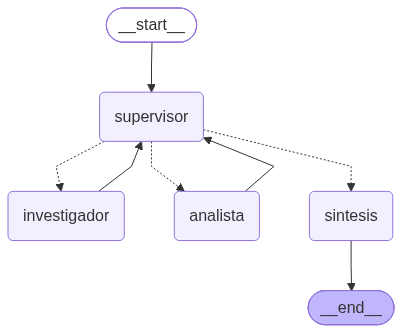

In [18]:
from IPython.display import Image, display

print(grafo.get_graph().draw_mermaid())

try:
    png = grafo.get_graph().draw_mermaid_png()
    with open("grafo.png", "wb") as f:
        f.write(png)
    display(Image(png))
except Exception as e:
    print(f"No se pudo generar la imagen ({type(e).__name__}); usá el texto Mermaid de arriba.")

## 17. Demo: flujo de delegación completo
La consulta obliga al supervisor a enviar la tarea al Investigador, pasar los datos al Analista, validar y cerrar con la síntesis.

In [38]:
from langgraph.errors import GraphRecursionError

CONSULTA = ("Estoy por comprar auriculares. Compará los Pulse X1 y los Nova Pro: qué opinan los clientes, "
            "el puntaje promedio de cada uno y cuál conviene más por relación precio/calidad.")

print(f"USUARIO: {CONSULTA}\n")
try:
    resultado = await grafo.ainvoke(
        {"messages": [HumanMessage(CONSULTA)], "contribuciones": [], "pasos_supervisor": 0},
        {"recursion_limit": RECURSION_LIMIT_GRAFO},
    )
    print("\n" + "=" * 70 + "\nRESPUESTA FINAL\n" + "=" * 70)
    print(resultado["respuesta_final"])
except GraphRecursionError:
    print(f"Se alcanzó el límite de {RECURSION_LIMIT_GRAFO} pasos del grafo")
except Exception as e:
    print(f"Error controlado ({type(e).__name__}): {e}")

USUARIO: Estoy por comprar auriculares. Compará los Pulse X1 y los Nova Pro: qué opinan los clientes, el puntaje promedio de cada uno y cuál conviene más por relación precio/calidad.



/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
13:10:13 | INFO    | orquestador | SUPERVISOR (paso 1) -> investigador | Todavía no hay contribuciones y se necesita que el investigador obtenga la información inicial de los productos solicitados.
13:10:23 | INFO    | orquestador |  investigador recibe: Busca el precio y todas las reseñas de los auriculares Pulse X1 y los Nova Pro en la base de datos.
/usr/local/lib/python3.13/dist-packages/google/genai/_common.py:642: RuntimeWarning: coroutine 'ClientResponse.json' was never awaited
  non_none_types = [arg for arg in args if arg is not type(None)]
13:10:32 | INFO    | orquestador |  buscar_productos('Pulse X1') -> 1 resultado(s)
13:10:32 | INFO    | orquestador |  buscar_productos('Nova Pro') -> 1 resultado(s)
13:10:52 | INFO    | orque


RESPUESTA FINAL
Aquí tenés la comparación detallada de los auriculares:

* **Comparación de productos:** 
  * **Pulse X1:** Precio de $45.000, 30 horas de batería, cancelación de ruido y garantía de 12 meses.
  * **Nova Pro:** Precio de $62.000, 40 horas de batería, cancelación de ruido y garantía de 18 meses.

* **Opinión de los clientes:**
  * **Pulse X1:** Los clientes destacan su excelente sonido, comodidad, buena batería y cancelación de ruido. Algunos mencionan que el estuche es frágil o que a veces se desconectan del celular, pero no registran reseñas negativas.
  * **Nova Pro:** Los usuarios elogian su sonido increíble, duración de batería, comodidad y cancelación de ruido. Como puntos negativos, algunos se quejan de que el micrófono es malo, que las orejas se calientan tras un rato y que son muy caros.

* **Puntajes promedio:**
  * **Pulse X1:** 4.2 / 5
  * **Nova Pro:** 3.8 / 5

* **Recomendación final:**
  Te conviene comprar los **Pulse X1**. Tienen un puntaje promedio sup

## 18. Traza del flujo de delegación
Reconstruye, desde el estado compartido, quién intervino, en qué orden y con qué aporte.

In [39]:
import json

flujo = ["supervisor" if m.name == "supervisor" else m.name
         for m in resultado["messages"] if isinstance(m, AIMessage)]

traza = {
    "consulta": CONSULTA,
    "modelos": {"supervisor_y_sintesis": MODELO_SUPERVISOR, "especialistas": MODELO_ESPECIALISTAS},
    "flujo": flujo,
    "pasos_supervisor": resultado["pasos_supervisor"],
    "tarea_completa": resultado["tarea_completa"],
    "decisiones_supervisor": [texto_de(m) for m in resultado["messages"]
                              if isinstance(m, AIMessage) and m.name == "supervisor"],
    "contribuciones": resultado["contribuciones"],
    "respuesta_final": resultado["respuesta_final"],
}

print("FLUJO:", " -> ".join(flujo), "-> END\n")
for i, m in enumerate(resultado["messages"][1:], start=1):
    if m.name == "supervisor":
        print(f"{i}. SUPERVISOR | {texto_de(m)}")
    elif m.name == "sintesis":
        print(f"{i}. SINTESIS   | respuesta final generada")
    else:
        c = next(c for c in resultado["contribuciones"] if c["resultado"] == texto_de(m))
        print(f"{i}. {m.name.upper():<10} | herramientas: {c['herramientas_usadas']}")

with open("traza_orquestador.json", "w", encoding="utf-8") as f:
    json.dump(traza, f, ensure_ascii=False, indent=2)
print("\nTraza guardada en traza_orquestador.json")

FLUJO: supervisor -> investigador -> supervisor -> analista -> supervisor -> sintesis -> END

1. SUPERVISOR | Decisión: investigador. Motivo: Todavía no hay contribuciones y se necesita que el investigador obtenga la información inicial de los productos solicitados.. Instrucción: Busca el precio y todas las reseñas de los auriculares Pulse X1 y los Nova Pro en la base de datos.
2. INVESTIGADOR | herramientas: ['buscar_productos', 'buscar_productos', 'obtener_resenas', 'obtener_resenas']
3. SUPERVISOR | Decisión: analista. Motivo: El investigador ya obtuvo los precios y reseñas, por lo que ahora el analista debe realizar los cálculos y la comparación solicitada.. Instrucción: Calcula el puntaje promedio de cada producto y analiza la relación precio/calidad para determinar cuál conviene más basándote en los precios y reseñas ya obtenidos.
4. ANALISTA   | herramientas: ['calcular_estadisticas', 'calcular_estadisticas', 'analizar_sentimiento', 'analizar_sentimiento', 'calcular', 'calcular'